In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from scipy.stats import entropy
import seaborn as sns
from os import listdir, makedirs
import pickle
import ast

In [2]:
# Data and figure path
DATA_PATH = '/Users/euanprentis/Documents/feat-predict_simulations/exp-8/data'
FORMATTED_DATA_PATH = '../data'
FIG_PATH = '../figs'
makedirs(FIG_PATH, exist_ok=True)
makedirs(FORMATTED_DATA_PATH, exist_ok=True)

# If overwrite is True, will overwrite existing formatted data
OVERWRITE = False

# Causal depth palettes
DEPTH_PALETTE_BW = sns.cubehelix_palette(4, hue=0, dark=.5, light=.9)
COLOR = "#b382a0"
DEPTH_PALETTE = sns.blend_palette(["white", COLOR, "black"], n_colors=6)[1:-1]

LABEL_PALETTE = {
    'dim1': '#3DB2FF',
    'dim2_ff': '#FF2442',
    'dim2_ff-biased': '.5'
}

# Load data

In [3]:
def information_from_label(model_label):
    """
    Get field information from model label

    Arguments
    ---------
    model_label : str
        model label
    
    Returns
    -------
    fields : dict
        Dictionary of field information
    """
    fields = {}
    for field in model_label.split('_'):
        if not '-' in field:
            continue
        key, value = field.split('-')
        fields[key] = value
    return fields

def convert_state_str(state_str):
    """
    Convert a string representation of a state to a numpy array.

    Arguments
    ---------
    state_str : str
        The string representation of the state.

    Returns
    -------
    state_arr : numpy.ndarray
        The numpy array representation of the state
    """
    state_str = state_str.replace('[ ', '[').replace('  ', ' ')
    state_str = state_str[1:-1]
    state_str = state_str.split(' ')
    state_arr = np.array(state_str, dtype=int)
    return state_arr

def load_from_dir(data_path, phase):
    """
    Load behavioral data for a given phase

    Arguments
    ---------
    data_path : str
        Path to the data directory
    phase : str
        The phase of the data to load

    Returns
    -------
    df : pandas.DataFrame
        The loaded data
    """
    df = []
    for env_label in listdir(data_path):
        if env_label[0] == '.':
            continue
        env_path = f'{data_path}/{env_label}'
        for model_label in listdir(env_path):
            if model_label[0] == '.':
                continue
            model_path = f'{env_path}/{model_label}'
            for sub_label in listdir(model_path):
                if sub_label[0] == '.':
                    continue
                phase_path = f'{model_path}/{sub_label}/{phase}'
                for f in listdir(phase_path):
                    if '.csv' in f:
                        this_df = pd.read_csv(
                            f'{phase_path}/{f}'
                        )
                        env_info = information_from_label(env_label)
                        for key, value in env_info.items():
                            this_df[key] = value
                        this_df['env_label'] = env_label
                        df.append(this_df)
    df = pd.concat(df)
    return df

def get_target_frequency(
        df,
        grouping_vars = [],
        state = 'target',
        binary_coding = True
        ):
    """
    Get the frequency of each target state within a group

    Arguments
    ---------
    df : pandas.DataFrame
        Behavioral data frame
    grouping_vars : list
        List of columns to group by
    state : str
        The state column to analyze
    binary_coding : bool
        Whether to use binary coding for the frequency column

    Returns
    -------
    df : pandas.DataFrame
        Data frame with added frequency column
    """

    # Create labels for the count, rate, and frequency columns
    count_label = f'count_{state}'
    rate_label = f'rate_{state}'
    freq_label = f'freq_{state}'

    # Get rates of each target per model and id
    target_counts = df.groupby(
        [*grouping_vars, state]
        ).size().reset_index(name=count_label)
    total_counts = target_counts.groupby(
        grouping_vars
        )[count_label].transform('sum')
    target_counts[rate_label] = target_counts[count_label]/total_counts

    # Find the highest and lowest rates per id and model
    highest_rate = target_counts.groupby(
        grouping_vars
        )[rate_label].transform('max')

    # Categorize each item
    if binary_coding:
        target_counts[freq_label] = target_counts[rate_label] == highest_rate
        target_counts[freq_label] = target_counts[freq_label].astype(int)
    df = pd.merge(
        df,
        target_counts,
    )

    return df

def count_causal(row, return_proportion=True):
    """
    Count the proportion (default) or number of possible causal
    inferences on a trial.

    Arguments
    ---------
    row : pandas.Series
        A row of the behavioral data frame
    return_proportion : bool
        Whether to return as proportion (True) or count (False)
    
    Returns
    -------
    n_causal : float
        The proportion/number of possible causal inferences
    """
    is_causal = row['options_comb_arr'] & row['target_comb_arr']
    n_causal = np.sum(is_causal)
    if return_proportion:
        n_causal = n_causal/row['dim']
    return n_causal

def count_spurious(row, clusters):
    """
    Count the proportion of spurious transitions on a trial.

    Arguments
    ---------
    row : pandas.Series
        A row of the behavioral data frame
    clusters : dict
        A dictionary of feature clusters for each dimension

    Returns
    -------
    p_spurious : float
        The proportion of spurious transitions
    """

    # No spurious transitions in one-dimensional environments
    if row['dim'] == 1:
        return 0  
    
    # Count causal transitions
    n_causal = count_causal(row, return_proportion=False)
    
    # Arrays represent the two clusters of feature combinations
    cluster = clusters[row['dim']]

    # Count total transitions within each cluster
    n_transitions = np.sum([
        np.prod([
            np.sum(row['options_comb_arr'].astype(bool) & cluster),
            np.sum(row['target_comb_arr'].astype(bool) & cluster)
        ]),
        np.prod([
            np.sum(row['options_comb_arr'].astype(bool) & ~cluster),
            np.sum(row['target_comb_arr'].astype(bool) & ~cluster)
        ])
    ])

    # Proportion of spurious transitions
    n_spurious = n_transitions - n_causal
    p_spurious = n_spurious/(row['dim']**2 - row['dim'])
    
    return p_spurious

def get_transition_proportions(df):
    """
    Get the proportion of causal and spurious transitions on each trial

    Arguments
    ---------
    df : pandas.DataFrame
        Behavioral data frame

    Returns
    -------
    df : pandas.DataFrame
        Behavioral data frame with added columns for p_causal and
        p_spurious
    """

    # Convert strings to arrays
    df['options_comb_arr'] = df['options_comb'].apply(convert_state_str)
    df['target_comb_arr'] = df['target_comb'].apply(convert_state_str)

    # Initialize transition proportion columns
    df['p_spurious'] = 0
    df['p_causal'] = 0

    # Compute p_causal
    df['p_causal'] = df.apply(count_causal, axis=1)

    # Define feature arrays for dim=2 and dim=4
    clusters = {
        2: np.array([1, 1, 0, 0], dtype=bool),
        4: np.array([1, 1, 1, 1, 0, 0, 0, 0], dtype=bool)
    }

    # Apply only where dim is 2 or 4
    idx = df['dim'] > 1
    df.loc[idx, 'p_spurious'] = df.loc[idx].apply(
        count_spurious,
        args = (clusters,),
        axis = 1
    )

    # Drop array columns
    df = df.drop(columns=['options_comb_arr', 'target_comb'])

    return df

def create_mask(n_features, n_categories=4):

    n_features_per_category = n_features/n_categories
    mask = np.repeat(
        np.repeat(
            np.eye(n_categories),
            n_features_per_category,
            axis = 1
        ),
        n_features_per_category,
        axis = 0
    )
    mask = mask - np.eye(len(mask))
    return mask


## Load training

In [4]:
# Load existing formatted data frame if it exists
training_fname = f'{FORMATTED_DATA_PATH}/training_df.csv'
if ('training_df.csv' in listdir(FORMATTED_DATA_PATH)) and not OVERWRITE:
    training_df = pd.read_csv(training_fname)

# Otherwise, load the data from the raw data
else:
    # Load all training data into one directory
    training_df = load_from_dir(DATA_PATH, 'training')

    # Make unused lmbd values 0 instead of NaN
    training_df['inference_power'] = training_df['inference_power'].fillna(1)

    # Format columns
    training_df['depth'] = training_df['depth'].astype(int)
    training_df['dim'] = training_df['dim'].astype(int)

    # Label target frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label']
    )

    # Label composition frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label'],
        state = 'composition',
        binary_coding = False
    )

    # Select columns
    training_df = training_df[[
        'id',
        'model_label',
        'inference_power',
        'alpha',
        'env_label',
        'depth',
        'dim',
        'trial',
        'options_comb',
        'target',
        'composition',
        'freq_target',
        'rate_composition',
        'p',
        'reward'
    ]]

    # Proportion of possible reward earned on each trial
    training_df['p_reward'] = training_df['reward']/training_df['dim']

    # Save the formatted data
    training_df.to_csv(training_fname, index=False)

training_df

,id,model_label,inference_power,alpha,env_label,depth,dim,trial,options_comb,target,composition,freq_target,rate_composition,p,reward,p_reward
0,388,ff-biased,1.000000,0.335038,depth-4_dim-2,4,2,1,[0 0 1 1],[ 0 0 1 10],[0 0 6 5],1,0.145370,0.250000,0,0.0
1,388,ff-biased,1.000000,0.335038,depth-4_dim-2,4,2,2,[1 1 0 0],[1 1 0 0],[5 5 0 0],0,0.121296,0.250000,2,1.0
2,388,ff-biased,1.000000,0.335038,depth-4_dim-2,4,2,3,[0 0 1 1],[ 0 0 1 10],[0 0 5 6],1,0.125000,0.250000,2,1.0
3,388,ff-biased,1.000000,0.335038,depth-4_dim-2,4,2,4,[0 0 1 1],[ 0 0 10 10],[0 0 6 6],0,0.112963,0.250000,2,1.0
4,388,ff-biased,1.000000,0.335038,depth-4_dim-2,4,2,5,[1 1 0 0],[1 1 0 0],[5 5 0 0],0,0.121296,0.244538,2,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12959995,385,ff,1.090505,0.083025,depth-3_dim-1,3,1,2156,[0 0 0 1],[0 0 0 1],[0 0 0 4],1,0.129167,0.983152,1,1.0
12959996,385,ff,1.090505,0.083025,depth-3_dim-1,3,1,2157,[0 0 0 1],[0 0 0 8],[0 0 0 5],1,0.120833,0.983152,1,1.0
12959997,385,ff,1.090505,0.083025,depth-3_dim-1,3,1,2158,[1 0 0 0],[8 0 0 0],[5 0 0 0],1,0.124074,0.983152,1,1.0
12959998,385,ff,1.090505,0.083025,depth-3_dim-1,3,1,2159,[1 0 0 0],[1 0 0 0],[4 0 0 0],1,0.125926,0.983152,1,1.0


## Load test

In [5]:
# Load existing formatted data frame if it exists
test_fname = f'{FORMATTED_DATA_PATH}/test_df.csv'
if ('test_df.csv' in listdir(FORMATTED_DATA_PATH)) and not OVERWRITE:
    test_df = pd.read_csv(test_fname)

# Otherwise, load the data from the raw data
else:

    # Load all test data into one directory
    test_df = load_from_dir(DATA_PATH, 'test')

    # Make unused lmbd values 0 instead of NaN
    test_df['inference_power'] = test_df['inference_power'].fillna(1)
    
    # Format columns
    test_df['depth'] = test_df['depth'].astype(int)
    test_df['dim'] = test_df['dim'].astype(int)

    # Label test targets/options as old (from training) or new
    for env_label in test_df['env_label'].unique():

        # Get targets and options seen during training
        idx = training_df['env_label'] == env_label
        training_targets = np.unique(training_df.loc[idx, 'target'])
        training_options = np.unique(training_df.loc[idx, 'options_comb'])

        # Label test targets and options as old or novel
        idx = test_df['env_label'] == env_label
        test_df.loc[idx, 'novel_target'] = np.isin(
            test_df.loc[idx, 'target'],
            training_targets,
            invert = True
        ).astype(int)
        test_df.loc[idx, 'novel_options'] = np.isin(
            test_df.loc[idx, 'options_comb'],
            training_options,
            invert = True
        ).astype(int)

    # Get trials where options and target features match
    test_df['options_target_comb_match'] = (
        test_df['options_comb'] == test_df['target_comb']
    ).astype(int)

    # Label test trials that would have been seen during training
    test_df['old'] = (
        np.logical_not(test_df['novel_target']) &
        np.logical_not(test_df['novel_options']) &
        test_df['options_target_comb_match']
    ).astype(int)

    # Label frequent old targets
    test_df = pd.merge(
        test_df,
        training_df[['id', 'env_label', 'target', 'freq_target']].drop_duplicates(),
        on=['id', 'env_label', 'target'],
        how='left'
    )
    idx = np.isnan(test_df['freq_target'])
    test_df.loc[idx, 'freq_target'] = -1

    # Select columns
    test_df = test_df[[
        'id',
        'model_label',
        'inference_power',
        'alpha',
        'depth',
        'dim',
        'options_comb',
        'target_comb',
        'target',
        'novel_target',
        'novel_options',
        'old',
        'freq_target',
        'reward'
    ]]

    # Get causal and spurious transition propostions
    test_df = get_transition_proportions(test_df)

    # Proportion of possible reward earned on each trial
    test_df['p_reward'] = (test_df['reward']/test_df['dim'])/(test_df['p_causal'])

    # Save the formatted data
    test_df.to_csv(test_fname, index=False)

test_df

,id,model_label,inference_power,alpha,depth,dim,options_comb,target,novel_target,novel_options,old,freq_target,reward,target_comb_arr,p_spurious,p_causal,p_reward
0,150,ff-biased,1.000000,0.908584,4,2,[1 1 0 0],[0 0 1 1],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN
1,150,ff-biased,1.000000,0.908584,4,2,[1 1 0 0],[ 0 0 1 10],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN
2,150,ff-biased,1.000000,0.908584,4,2,[1 1 0 0],[ 0 0 10 1],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN
3,150,ff-biased,1.000000,0.908584,4,2,[1 1 0 0],[ 0 0 10 10],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN
4,150,ff-biased,1.000000,0.908584,4,2,[1 1 0 0],[0 1 0 1],1.0,0.0,0,-1.0,1,[0 1 0 1],0.5,0.5,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
703995,149,ff,4.322912,0.881308,3,1,[0 0 0 1],[0 0 8 0],0.0,0.0,0,1.0,0,[0 0 1 0],0.0,0.0,NaN
703996,149,ff,4.322912,0.881308,3,1,[0 0 0 1],[0 1 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN
703997,149,ff,4.322912,0.881308,3,1,[0 0 0 1],[0 8 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN
703998,149,ff,4.322912,0.881308,3,1,[0 0 0 1],[1 0 0 0],0.0,0.0,0,1.0,0,[1 0 0 0],0.0,0.0,NaN


In [6]:
grouping_variables = [
    'depth',
    'dim',
    'id',
    'model_label',
    'inference_power',
    'alpha'
]
idx = (test_df['p_causal'] > 0) & (test_df['old'] == 1)
test_summary = test_df.loc[idx, [*grouping_variables, 'reward', 'p_reward']]
test_summary = test_summary.groupby(grouping_variables)
test_summary = test_summary.mean()
test_summary = test_summary.reset_index()
test_summary

,depth,dim,id,model_label,inference_power,alpha,reward,p_reward
0,1,1,1,ff,0.000572,0.417022,0.750,0.7500
1,1,1,1,ff-biased,1.000000,0.417022,0.750,0.7500
2,1,1,2,ff,2.748312,0.435995,0.875,0.8750
3,1,1,2,ff-biased,1.000000,0.435995,0.875,0.8750
4,1,1,3,ff,1.454524,0.550798,0.875,0.8750
...,...,...,...,...,...,...,...,...
7995,4,2,498,ff-biased,1.000000,0.209054,2.000,1.0000
7996,4,2,499,ff,1.924540,0.953811,0.500,0.2500
7997,4,2,499,ff-biased,1.000000,0.953811,1.125,0.5625
7998,4,2,500,ff,3.333058,0.693680,1.000,0.5000


## Subject information

In [7]:
subj_df = test_summary[['id', 'model_label', 'inference_power', 'alpha']]
subj_df = subj_df.drop_duplicates()
subj_df = subj_df.reset_index(drop=True)
subj_df

,id,model_label,inference_power,alpha
0,1,ff,0.000572,0.417022
1,1,ff-biased,1.000000,0.417022
2,2,ff,2.748312,0.435995
3,2,ff-biased,1.000000,0.435995
4,3,ff,1.454524,0.550798
...,...,...,...,...
995,498,ff-biased,1.000000,0.209054
996,499,ff,1.924540,0.953811
997,499,ff-biased,1.000000,0.953811
998,500,ff,3.333058,0.693680


## Load Representations

In [8]:
def convert_states_to_labels(states):
    """
    Convert array of states to string labels

    Arguments
    ---------
    states : np.ndarray
        Array represent states by their features

    Returns
    -------
    labels : list
        state labels
    """
    labels = [''.join(label) for label in states.astype(str)]
    return labels

def standardize_reps_order(reps):
    """
    Standardize the order of representations

    Arguments
    ---------
    reps : dict
        representation dictionary

    Returns
    -------
    reps : dict
        standardized representation dictionary
    """
    
    # Get indices for standardized ordering
    idx_sorted_S = np.lexsort(reps['S'].T[::-1])
    idx_sorted_F = np.lexsort(reps['F_raw'].T[::-1])
    S = reps['S'][idx_sorted_S]
    F_raw = reps['F_raw'][idx_sorted_F]

    # Re-order rows by whether starts are conjunctive or not
    conjunctive_starts = False
    if 'conjunctive_starts' in reps['agent_info']:
        if reps['agent_info']['conjunctive_starts']:
            conjunctive_starts = True
    if conjunctive_starts:
            M = reps['M'][idx_sorted_S]
            bias = reps['bias'][idx_sorted_S]
            row_labels = convert_states_to_labels(S)
    else:
        M = reps['M'][idx_sorted_F]
        bias = reps['bias'][idx_sorted_F]
        row_labels = convert_states_to_labels(F_raw)

    # Re-order columns by whether successors are conjunctive or not
    conjunctive_successors = False
    if 'conjunctive_successors' in reps['agent_info']:
        if reps['agent_info']['conjunctive_successors']:
            conjunctive_successors = True
    if conjunctive_successors:
        M = M.T[idx_sorted_S].T
        bias = bias.T[idx_sorted_S].T
        col_labels = convert_states_to_labels(S)
    else:
        M = M.T[idx_sorted_F].T
        bias = bias.T[idx_sorted_F].T
        col_labels = convert_states_to_labels(F_raw)

    # Assign re-ordered representations
    reps['S'] = S
    reps['F_raw'] = F_raw
    reps['M'] = M
    reps['bias'] = bias
    reps['row_labels'] = row_labels
    reps['col_labels'] = col_labels

    return reps

def get_label_matrix(features):
    """
    Get a label matrix that reflects every conjunction of features

    Arguments
    ---------
    features : np.ndarray
        Array of features

    Returns
    -------
    label_matrix : np.ndarray
        Label matrix
    """
    n_features = len(features)
    label_matrix = np.zeros((n_features, n_features), dtype=object)
    for i, feature_i in enumerate(features):
        for j, feature_j in enumerate(features[i:], start=i):

            # Cannot have a conjunction of features from one category
            cat_i = feature_i.astype(bool)
            cat_j = feature_j.astype(bool)
            same_category = np.all(cat_i == cat_j)
            if same_category:
                label = 'None'

            # Conjunction of features from different categories
            else:
                label = str(feature_i + feature_j)

            # Assign labels to the matrix
            label_matrix[i, j] = label
            label_matrix[j, i] = label
    return label_matrix

def load_representations(data_path):
    """
    Load successor matrices and label matrices

    Arguments
    ---------
    data_path : str
        Path to the data directory
    
    Returns
    -------
    representations : dict
        Dictionary of successor matrices
    label_matrices : dict
        Dictionary of label matrices
    """
    representations = {}
    label_matrices = {}
    for env_label in listdir(data_path):
        if env_label[0] == '.':
            continue
        dim = int(information_from_label(env_label)['dim'])
        depth = int(information_from_label(env_label)['depth'])
        env_path = f'{data_path}/{env_label}'
        for model_label in listdir(env_path):
            if model_label[0] == '.':
                continue
            model_path = f'{env_path}/{model_label}'
            for sub_label in listdir(model_path):
                if sub_label[0] == '.':
                    continue
                reps_path = f'{model_path}/{sub_label}/representations'
                for fname in listdir(reps_path):
                    if '.pkl' not in fname:
                        continue
                    agent_id = int(fname.replace('.pkl', '').split('_')[1])
                    key = (dim, depth, sub_label, agent_id)
                    with open(f'{reps_path}/{fname}', 'rb') as f:

                        # Load representations in a standardized order
                        reps = standardize_reps_order(pickle.load(f))

                        # Extract successor matrix
                        representations[key] = reps['M']

                        # Extract label matrix 
                        label_matrices[key] = get_label_matrix(reps['F_raw'])

    return representations, label_matrices

In [9]:
representations, label_matrices = load_representations(DATA_PATH)

# Analyze Behavior

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_86472/789036270.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df['inference_power_bin'] = pd.cut(
/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_86472/789036270.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df['inference_power_bin'] = pd.cut(


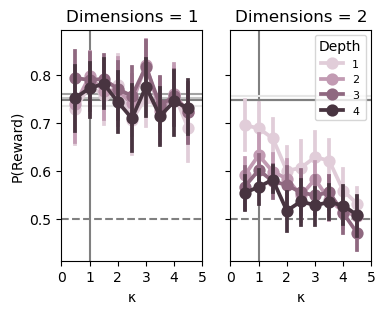

In [10]:
dim_labels = np.unique(test_summary['dim'])
n_subplots = len(dim_labels)

fig, axs = plt.subplots(1, n_subplots, figsize=(n_subplots*2, 3), sharey=True)

for i, dim in enumerate(dim_labels):
    ax = axs[i]
    ax.axhline(0.5, c='0.5', ls='--')
    ax.axvline(1, c='0.5')

    # Plot causal learner
    for depth in np.unique(test_summary['depth']):
        idx = (
            (test_summary['dim'] == dim) &
            (test_summary['depth'] == depth) &
            (test_summary['model_label'] == 'ff-biased')
            )
        causal_avg_reward = test_summary.loc[idx, 'p_reward'].mean()
        ax.axhline(causal_avg_reward, c=DEPTH_PALETTE_BW[depth - 1])

    # Plot unbiased learner
    idx = (
        (test_summary['dim'] == dim) &
        (test_summary['model_label'] == 'ff')
    )
    plot_df = test_summary.loc[idx]
    plot_df['inference_power_bin'] = pd.cut(
        plot_df['inference_power'],
        bins = np.linspace(0.25, 4.75, 10)
    )
    sns.pointplot(
        data = plot_df,
        x = 'inference_power_bin',
        y = 'p_reward',
        hue = 'depth',
        palette = DEPTH_PALETTE,
        ax = ax
    )
    ax.set_title(f'Dimensions = {dim}')
    ax.set_xlabel('κ')
    if i == 0:
        ax.set_ylabel('P(Reward)')
    else:
        ax.set_ylabel(None)
    if i < len(dim_labels) - 1:
        ax.get_legend().remove()
    else:
        ax.legend(title='Depth', fontsize=8)
    ax.set_xticks(np.arange(-1, 10, 2))
    ax.set_xticklabels(np.arange(6))

fig.savefig(
    f'{FIG_PATH}/test-old-preward-by-inference-power.pdf',
    dpi = 300,
    bbox_inches = 'tight'
    )


# Analyze Spurious Information In Representations

In [11]:
def get_M_inference(M, inference_power):
    M_rowsum = np.sum(np.abs(M), axis=1)
    M_inference = np.sign(M)*(M**inference_power)
    sum_denom = np.sum(M_inference, axis=1, keepdims=True)
    zero_rows = (sum_denom == 0).flatten()
    sum_denom[zero_rows] = 1
    M_inference[zero_rows] = M[zero_rows]
    M_inference = M_inference/sum_denom
    M_inference = M_rowsum.reshape(-1, 1)*M_inference
    return M_inference

In [12]:
# Get unbiased learner IDs
depth_levels = np.sort(test_summary['depth'].unique())
ff_ids = np.unique(subj_df['id'])

# Analyze at each level of depth
rep_correlations = []
rep_mass = []
for depth in depth_levels:
    for subj in ff_ids:

        # Compute the difference between the unbiased and causal
        # learner representations at matched parameter values
        M = representations[(2, depth, 'ff', subj)]
        M_biased = representations[(2, depth, 'ff-biased', subj)]

        # Get inference power 
        idx = (
            (subj_df['id'] == subj) &
            (subj_df['model_label'] == 'ff') 
        )
        inference_power = subj_df.loc[idx, 'inference_power'].values[0]

        # Get M at inference by applying the inference power parameter
        M = get_M_inference(M, inference_power)
        M_biased = get_M_inference(M_biased, inference_power)

        try:
            M_diff = M - M_biased
        except:
            continue

        # Compute causal and spurious masks on the successor matrices
        causal_mask = np.ceil(M_biased/np.max(M_biased))
        causal_mask -= np.eye(len(causal_mask))
        spur_mask = (1 - causal_mask - np.eye(len(causal_mask)))
        non_eye_mask = np.logical_not(np.eye(len(M_biased))).astype(int)

        # Analyze spurious information by distance from terminal state
        steps_from_terminal = np.tile(
            [*range(depth + 1), *range(depth + 1)[::-1]],
            4
        )
        for steps in range(1, depth + 1):
            idx = steps_from_terminal == steps

            # Correlation between biased and unbiased learners'
            # successor matrices 
            corr = np.corrcoef(
                M[idx].flatten(),
                M_biased[idx].flatten()
            )[0, 1]
            rep_correlations = rep_correlations + [{
                'depth': depth,
                'id': subj,
                'steps_from_terminal': steps,
                'corr': corr
            }]

            # Proportion of spurious information in the unbiased
            # learner's successor matrix
            sum_spur = np.sum(M[idx]*spur_mask[idx], axis=1)
            sum_causal = np.sum(M[idx]*causal_mask[idx], axis=1)
            sum_pred = np.sum(M[idx]*non_eye_mask[idx], axis=1)
            sum_all = np.sum(M[idx], axis=1)
            p_spur = np.mean(sum_spur/sum_all)
            p_causal = np.mean(sum_causal/sum_all)
            p_pred = np.mean(sum_pred/sum_all)
            rep_mass.append({
                'depth': depth,
                'id': subj,
                'steps_from_terminal': steps,
                'p_spur': p_spur,
                'p_causal': p_causal,
                'p_pred': p_pred,
                'pred': np.mean(sum_pred)
            })
              
# To dataframes
rep_correlations = pd.DataFrame(rep_correlations)
rep_mass = pd.DataFrame(rep_mass)

# Add parameter information
rep_correlations = pd.merge(
    rep_correlations,
    subj_df[['id', 'inference_power']]
)
rep_mass = pd.merge(
    rep_mass,
    subj_df[['id', 'inference_power']]
)

# Bin parameter values for plotting
rep_correlations['inference_power_bin'] = pd.cut(
    rep_correlations['inference_power'],
    bins = np.linspace(0.25, 4.75, 10)
)
rep_mass['inference_power_bin'] = pd.cut(
    rep_mass['inference_power'],
    bins = np.linspace(0.25, 4.75, 10)
)


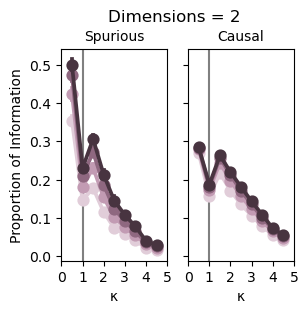

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(3, 3), sharey=True)

for i, yvar in enumerate(['p_spur', 'p_causal']):
    ax = axs[i]
    ax.axvline(1, c='0.5')
    sns.pointplot(
        data = rep_mass,
        x = 'inference_power_bin',
        y = yvar,
        hue = 'depth',
        palette = DEPTH_PALETTE,
        ax = ax
    )
    ax.get_legend().remove()
    ax.set_xlabel('κ')
    ax.set_ylabel('Proportion of Information')
    ax.set_title(['Spurious', 'Causal'][i], fontsize=10)
    ax.set_xticks(np.arange(-1, 10, 2))
    ax.set_xticklabels(np.arange(6))
    ax.set_box_aspect(2)
fig.suptitle('Dimensions = 2', fontsize=12)
fig.savefig(
    f'{FIG_PATH}/predictive-info.pdf',
    dpi = 300,
    bbox_inches = 'tight'
    )

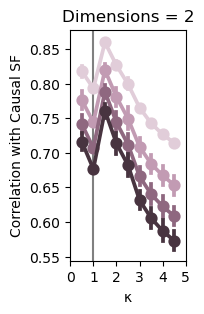

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(1.5, 3))
ax.axvline(1, c='0.5')
sns.pointplot(
    data = rep_correlations,
    x = 'inference_power_bin',
    y = 'corr',
    hue = 'depth',
    palette = DEPTH_PALETTE,
    ax = ax
)
ax.get_legend().remove()
ax.set_xlabel('κ')
ax.set_ylabel('Correlation with Causal SF')
ax.set_title('Dimensions = 2')
ax.set_xticks(np.arange(-1, 10, 2))
ax.set_xticklabels(np.arange(6))
ax.set_box_aspect(2)
fig.savefig(
    f'{FIG_PATH}/causal-correlation.pdf',
    dpi = 300,
    bbox_inches = 'tight'
    )
